In [13]:
import numpy as np
from matplotlib import pyplot as plt
N=290
data=np.random.choice([0,1],size=N)
nt=100
d_theta=1.0/nt
thetas=np.arange(d_theta/2,1,d_theta)

#copy pasting some of the functions from the original notebook

def likelihood(theta, data):
    """Assumes that theta and data are scalars"""
    theta**data*(1-theta)**(1-data)

def joint_likelihood(theta, data):
    """Assumes that theta is a scalar, data is an array."""
    return np.prod(np.pow(theta, data)*np.pow(1-theta, 1-data))

def prior_func(theta):
    if (theta < 0.0) or (theta > 1.0):
        return 0.0
    else:
        return 1.0

def integral_dnr(l, prior, dtheta):
    """Assumes that l and prior are uniformly discretized"""
    return np.sum(l*prior)*dtheta
    
def calc_posterior(theta, data, prior, likelihood):
    """Assumes that theta is uniformly spaced."""
    lh = likelihood(theta, data)
    d_theta = theta[1] - theta[0]
    dnr = integral_dnr(lh, prior, d_theta)
    post = lh*prior/dnr
    return post

lh = []
for t in thetas:
    lh.append(joint_likelihood(t, data))
lh = np.array(lh)

prior=np.asarray([prior_func(t) for t in thetas])
dnr=integral_dnr(lh,prior,d_theta)
posterior=prior*lh/dnr

#question 1 
estimatorofbayes=np.sum(thetas*posterior)*d_theta

n = len(data)
heads = np.sum(data)
estimatoroftextbook=(heads+1)/(n+2)

print("Number of tosses, heads and tails:", n,heads," and offer him m p")
print("Number of heads:", heads)
print("Number of tails:", n - heads)
print("Numerical estimate:",estimatorofbayes)
print("Textbook estimate:",estimatoroftextbook)
print("Absolute difference:",abs(estimatorofbayes-estimatoroftextbook))



Number of tosses, heads and tails: 290 149  and offer him m p
Number of heads: 149
Number of tails: 141
Numerical estimate: 0.513698630136986
Textbook estimate: 0.5136986301369864
Absolute difference: 3.3306690738754696e-16



Number of samples: 5
Number of heads: 0
Bayes estimator: 0.469291741035231

Number of samples: 10
Number of heads: 1
Bayes estimator: 0.4556796444027702

Number of samples: 20
Number of heads: 5
Bayes estimator: 0.44990784424564373


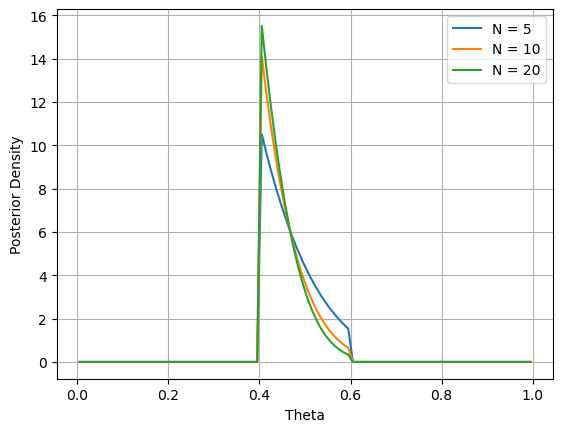

In [14]:
#question 2
prior_new=np.where((thetas>= 0.4) & (thetas <= 0.6),5.0,0.0)

for N in [5, 10, 20]:
    sample=data[:N]
    
    posterior_new = calc_posterior(thetas,sample, prior_new,lambda theta,d: theta**np.sum(d) * (1-theta)**(len(d)-np.sum(d))    )
    estimator = np.sum(thetas*posterior_new)*d_theta
    print("\nNumber of samples:",N)
    print("Number of heads:",np.sum(sample))
    print("Bayes estimator:", estimator)

    # Plot posterior
    plt.plot(thetas, posterior_new, label=f'N = {N}')
plt.xlabel("Theta")
plt.ylabel("Posterior Density")
plt.legend()
plt.grid()
plt.show()


Issue with this is all values outside 0.4-0.6 have prior probability zero, to fix this we can choose a prior distribution which allows all possible values to be between 0 and 1. 

Actual probability of heads: 0.7
Total tosses: 100
Number of heads: 70
Number of tails: 30


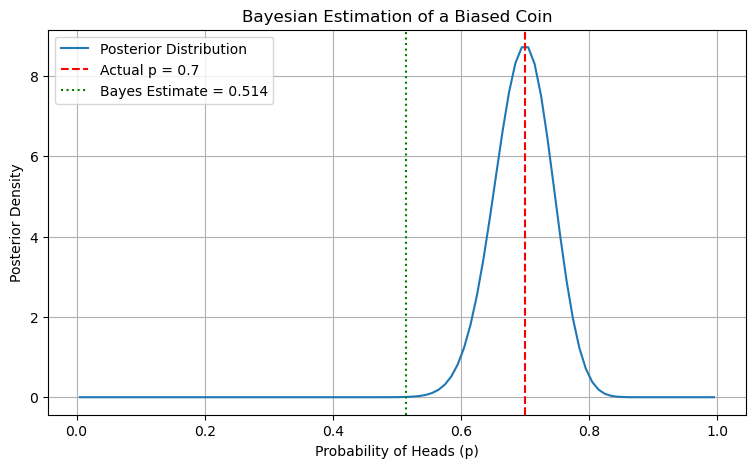

N = 5 | Bayes estimate = 0.5714
N = 10 | Bayes estimate = 0.5833
N = 20 | Bayes estimate = 0.6818
N = 50 | Bayes estimate = 0.7692
N = 100 | Bayes estimate = 0.6961


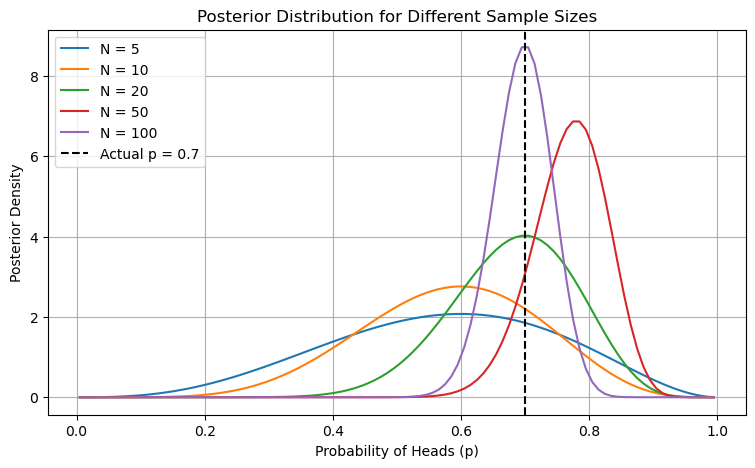

In [17]:
#question 3

np.random.seed(42)
true_p=0.7
N=100
data=np.random.binomial(1,true_p,size=N)
print("Actual probability of heads:",true_p)
print("Total tosses:",N)
print("Number of heads:",np.sum(data))
print("Number of tails:",N-np.sum(data))


nt=100
d_theta=1.0/nt
thetas=np.arange(d_theta/2,1,d_theta)
prior=np.ones(len(thetas))
likelihoods=np.array([joint_likelihood(t,data) for t in thetas])

unnormalized_posterior=likelihoods*prior
posterior=unnormalized_posterior/(np.sum(unnormalized_posterior)*d_theta)

plt.figure(figsize=(9,5))
plt.plot(thetas,posterior,label="Posterior Distribution")
plt.axvline(true_p,color='red',linestyle='--',label="Actual p = 0.7")
plt.axvline(estimatorofbayes,color='green',linestyle=':',label=f"Bayes Estimate = {estimatorofbayes:.3f}")
plt.xlabel("Probability of Heads (p)")
plt.ylabel("Posterior Density")
plt.title("Bayesian Estimation of a Biased Coin")
plt.legend()
plt.grid()
plt.show()


sample_sizes=[5,10,20,50,100]
plt.figure(figsize=(9,5))
for N in sample_sizes:
    sample=data[:N]
    likelihoods=np.array([joint_likelihood(t,sample) for t in thetas])
    posterior_temp=likelihoods*prior
    posterior_temp=posterior_temp/(np.sum(posterior_temp)*d_theta)
    estimate=np.sum(thetas*posterior_temp)*d_theta
    print("N =",N,"| Bayes estimate =",round(estimate,4))
    plt.plot(thetas,posterior_temp,label=f"N = {N}")
plt.axvline(true_p,color='black',linestyle='--',label="Actual p = 0.7")
plt.xlabel("Probability of Heads (p)")
plt.ylabel("Posterior Density")
plt.title("Posterior Distribution for Different Sample Sizes")
plt.legend()
plt.grid()
plt.show()